# Week 10 – Phân cụm và đối chiếu với nhận xét Tuần 9 (Nhóm 07)
**Nhóm 07 – lớp 62FIT4MLA – CLC01.** Notebook này gom các việc Tuần 9 (theo nhận xét của thầy Khánh) và nội dung Tuần 10 (phân cụm, nối với Gauss và hiệp phương sai).

**Đối chiếu nhận xét Tuần 9**

| Yêu cầu của thầy | Mục | Trạng thái |
|---|---|---|
| 1. In ID–text–label trước fit; kiểm lệch hàng; kiểm fold áp đúng X, y | 2 | Đã thêm; chạy trên dữ liệu dự án |
| 1b. Giải thích kết quả TF-IDF 0,841 và 0,336 | 3 | Đã thêm, có bằng chứng; khác với nhận định của thầy (xem mục 3) |
| 2. Cố định seed, lưu danh sách fold, chạy lại phải khớp | 2 | Đã thêm (`folds_w10.json`) |
| 3. Giữ bảng log loss LR; NB xuống phụ lục | Notebook W9 | Không thuộc Tuần 10; NB nằm ở notebook W9 |
| 4. Trích dẫn Lee et al. (2021), bỏ Pan nếu không tìm được | 9 | Đã xác minh Lee et al. (5-fold 80/10/10, không nêu gộp theo bài). Chỉ số RA chưa tìm thấy trong bài Pan et al.; bỏ Pan nếu không tìm được |
| Đọc ≥ 10 ca nhầm, bắt đầu từ WNL Glastonbury; tách lỗi tiền xử lý với độ khó | 6 | Đã điền (Claude đọc toàn văn, 25/10/2026); nhóm xem lại |
| So xếp hạng trong bài với gán mức tuyệt đối | 7 | Đã thêm |
| 5 văn bản ngoài, nhãn gán độc lập trước khi chạy mô hình | 8 | Đã điền 5 văn bản; nhãn do Claude gán trước khi chạy mô hình (25/10/2026 14:10), nhóm cần rà lại |
| BERT không bắt buộc | 10 | Không thực hiện trong notebook này |
| Hai câu hỏi tự trả lời | 10 | Đã thêm |

## 0. Chuẩn bị

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(0)   # cố định seed để kết quả tái lập được

## 1. Ôn lại Tuần 9 (ví dụ slide, kiểm tra bằng code)

In [12]:
class0 = np.array([[4,3],[6,7],[8,5],[10,9]], dtype=float)     # D1..D4
class1 = np.array([[12,11],[14,15],[16,13],[18,17]], dtype=float)  # P1..P4

mu0, mu1 = class0.mean(axis=0), class1.mean(axis=0)
assert np.allclose(mu0, [7, 6]) and np.allclose(mu1, [15, 14])

def sq_dist(x, c):
    # D² = (x1 - c1)² + (x2 - c2)², như slide Tuần 9 Part 1, slide 34
    return ((x - c) ** 2).sum(axis=-1)

N1, N2 = np.array([11, 12.]), np.array([9, 11.])
assert sq_dist(N1, mu0) == 52 and sq_dist(N1, mu1) == 20
assert sq_dist(N2, mu0) == 29 and sq_dist(N2, mu1) == 45

# Phương sai mẫu chia cho n (như slide): fractions lớp 0 = 5
assert np.isclose(np.var(class0[:, 0]), 5.0)
print("Các phép kiểm khớp slide Tuần 9.")

Các phép kiểm khớp slide Tuần 9.


### 1b. Hai ý khác từ slide Tuần 9
Mật độ là chiều cao, xác suất là diện tích (slide Part 1). Thiếu dữ liệu không phải 0 (slide Part 1 và Part 2).

In [13]:
from scipy.stats import norm
sd = np.sqrt(5.0)
assert norm.pdf(6, 7, sd) > norm.pdf(10, 7, sd)          # 6 gần µ hơn 10
prob_6_8 = norm.cdf(8, 7, sd) - norm.cdf(6, 7, sd)        # diện tích = xác suất
print('P(6 ≤ X ≤ 8) =', round(prob_6_8, 3), '(diện tích, không phải chiều cao)')

decimals_resp = np.array([14.0, np.nan, 9.0, 12.0])
mean_observed = np.nanmean(decimals_resp)
mean_if_zero = np.nan_to_num(decimals_resp).mean()
print('Trung bình trên quan sát được:', round(mean_observed, 2), '| nếu điền 0 (sai):', round(mean_if_zero, 2))
assert not np.isclose(mean_observed, mean_if_zero)

P(6 ≤ X ≤ 8) = 0.345 (diện tích, không phải chiều cao)
Trung bình trên quan sát được: 11.67 | nếu điền 0 (sai): 8.75


## 2. Việc 1: kiểm tra trước khi fit
Trước khi fit, in mẫu ID–text–label, kiểm hai bảng có cùng thứ tự hàng, và cố định fold. Nếu hàng lệch, mọi số liệu sau đó đều sai. Phần này chỉ chạy khi notebook dự án đã có `data`, `df`, `EXP`.

In [14]:
import os, json
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity

LEVELS_W10 = ['Elementary', 'Intermediate', 'Advanced']
ORD_W10 = {l: i for i, l in enumerate(LEVELS_W10)}
FOLD_FILE = 'folds_w10.json'

if 'data' not in globals() or 'df' not in globals() or 'EXP' not in globals():
    print('Bỏ qua mục 2, 3, 6, 7, 8: cần data, df, EXP từ Group07_Notebook.ipynb. Mở notebook đó, chạy đến hết mục 8, rồi chạy lại notebook này.')
else:
    # 2a. Hai bảng phải cùng thứ tự hàng
    assert len(data) == len(df), 'Số hàng khác nhau giữa văn bản và đặc trưng'
    assert (data.article.values == df.article.values).all() and (data.level.values == df.level.values).all(), \
        'LỆCH HÀNG giữa văn bản và đặc trưng: sửa trước khi làm mọi việc khác'
    texts = data.text.values
    y = df.level.map(ORD_W10).values
    groups = df.article.values
    assert len(texts) == len(y) == len(groups) == len(df)

    # 2b. In mẫu ID–text–label trước fit
    print('Mẫu ID | text | nhãn (trước fit):')
    for i in [0, 1, 2]:
        print(f'  {df.article.iloc[i]} | {df.level.iloc[i]} -> nhãn {y[i]} | {texts[i][:60]!r}')

    # 2c. Fold cố định; lưu ra file; chạy lại phải khớp
    def make_folds(seed=0):
        return [{'train': tr.tolist(), 'test': te.tolist()}
                for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups)]
    folds = make_folds(0)
    cover = np.zeros(len(y), int)
    for f in folds:
        assert not set(groups[f['train']]) & set(groups[f['test']]), 'Một bài nằm ở cả train và test'
        cover[f['test']] += 1
    assert (cover == 1).all(), 'Mỗi văn bản phải nằm đúng một lần trong test'
    if os.path.exists(FOLD_FILE):
        assert json.load(open(FOLD_FILE, encoding='utf-8')) == folds, 'Fold khác file đã lưu: kiểm tra seed và dữ liệu'
        print('Fold khớp với', FOLD_FILE)
    else:
        json.dump(folds, open(FOLD_FILE, 'w', encoding='utf-8'))
        print('Đã lưu fold ra', FOLD_FILE)

Mẫu ID | text | nhãn (trước fit):
  Amazon | Elementary -> nhãn 0 | '\ufeffWhen you see the word Amazon, what’s the first thing you th'
  Amsterdam | Elementary -> nhãn 0 | '\ufeffTo tourists, Amsterdam still seems very liberal. Recently t'
  Anita | Elementary -> nhãn 0 | '\ufeffAnitta, a music star from Brazil, has millions of fans, but'
Đã lưu fold ra folds_w10.json


## 3. Việc 1 (tiếp): vì sao chia ngẫu nhiên cho 0,336
Nhận xét của thầy: chia ngẫu nhiên để ba phiên bản của cùng một bài nằm ở cả hai phía, nên accuracy chỉ có thể **cao hơn hoặc bằng** chia theo bài. Lý do: láng giềng gần nhất của một bản thường là bản khác của cùng bài, nên khi chia ngẫu nhiên, mô hình học được từ vựng riêng của bài rồi nhận ra nó ở bản còn lại (rò rỉ theo bài).

Kết quả của nhóm đi ngược chiều: chia ngẫu nhiên 0,336 thấp hơn chia theo bài 0,841. Trước hết kiểm tra căn chỉnh (ô 8): nếu ô 8 báo hai bảng cùng thứ tự hàng và fold áp đúng X, y thì không phải lỗi lệch hàng. Phần còn lại được giải thích bằng hiệu ứng cùng bài: láng giềng gần nhất của mỗi bản thường là bản anh em có nhãn khác (ô 10 đo khoảng 98% cùng bài, khoảng 1% cùng mức). Mô hình học từ vựng của bài nên đoán ngược mức của bản anh em, nên chia ngẫu nhiên thấp hơn cả mức đoán bừa. Nếu ô 8 đúng, đây là đặc điểm của dữ liệu và cách chia, không phải lỗi mã; nhưng nó bác bỏ nhận định “chia ngẫu nhiên chỉ có thể cao hơn hoặc bằng”, cần trao đổi với thầy.

Chỉ ghi số liệu vào báo cáo sau khi ô 10 chạy lại trên dữ liệu đã sửa. Điều này cần trao đổi với thầy trước khi viết vào báo cáo.

In [15]:
if 'folds' in globals():
    M = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    S = cosine_similarity(M); np.fill_diagonal(S, -1)
    nn = S.argmax(axis=1)
    print('Láng giềng gần nhất cùng bài:', round((groups[nn] == groups).mean(), 3))
    print('Láng giềng gần nhất cùng mức:', round((y[nn] == y).mean(), 3))

    rand_folds = [{'train': tr.tolist(), 'test': te.tolist()}
                  for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(texts, y)]
    def tfidf_acc(fs):
        accs = []
        for f in fs:
            tr, te = np.array(f['train']), np.array(f['test'])
            m = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                              LogisticRegression(C=30, max_iter=3000)).fit(texts[tr], y[tr])
            accs.append(accuracy_score(y[te], m.predict(texts[te])))
        return float(np.mean(accs))
    print('TF-IDF + LR, chia theo bài gốc:', round(tfidf_acc(folds), 3))
    print('TF-IDF + LR, chia ngẫu nhiên:  ', round(tfidf_acc(rand_folds), 3))

Láng giềng gần nhất cùng bài: 0.981
Láng giềng gần nhất cùng mức: 0.011


TF-IDF + LR, chia theo bài gốc: 0.838


TF-IDF + LR, chia ngẫu nhiên:   0.337


## 4. Phân cụm khi không có nhãn (Tuần 10)

### 4.1 Khi không có nhãn
Trong Tuần 9, tâm lớp được tính bằng cách lấy trung bình các bản ghi **có nhãn**. Ở đây ta bỏ nhãn đi. Lúc này không thể tính µ0 và µ1 trực tiếp, vì không biết bản ghi nào thuộc lớp nào. Phân cụm giải quyết bằng cách lặp: đoán tâm, gán điểm vào tâm gần nhất, rồi cập nhật tâm.

In [16]:
X = np.vstack([class0, class1])   # 8 điểm, nhãn đã bị bỏ đi
print("Hình dạng dữ liệu không nhãn:", X.shape)

Hình dạng dữ liệu không nhãn: (8, 2)


### 4.2 K-means tự viết
Mỗi vòng lặp có hai bước, đều dùng lại công thức của Tuần 9:
- **Gán:** mỗi điểm vào tâm có khoảng cách bình phương nhỏ nhất.
- **Cập nhật:** mỗi tâm trở thành trung bình các điểm được gán vào nó (cùng phép trung bình theo từng đặc trưng như slide 8–9 Tuần 9).

In [17]:
def kmeans_scratch(X, centres, max_iter=100):
    centres = np.array(centres, dtype=float)
    for it in range(1, max_iter + 1):
        d = np.stack([sq_dist(X, c) for c in centres], axis=1)   # n × k
        labels = d.argmin(axis=1)
        new = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centres[k]
                        for k in range(len(centres))])
        if np.allclose(new, centres):
            break
        centres = new
    return labels, centres, it

# Khởi tạo: một điểm từ mỗi nhóm (chỉ để minh hoạ, không dùng nhãn)
labels, centres, n_it = kmeans_scratch(X, centres=[[4, 3], [12, 11]])
print("Số vòng lặp:", n_it)
print("Tâm cuối:\n", centres)
# Kiểm tra: phân hoạch phải khớp với nhóm thật (D1..D4 một cụm, P1..P4 một cụm)
assert len(set(labels[:4])) == 1 and len(set(labels[4:])) == 1 and labels[0] != labels[4]
assert np.allclose(centres[labels[0]], mu0) and np.allclose(centres[labels[4]], mu1)
print("K-means tự viết khôi phục đúng hai nhóm.")

Số vòng lặp: 3
Tâm cuối:
 [[ 7.  6.]
 [15. 14.]]
K-means tự viết khôi phục đúng hai nhóm.


Kiểm tra lại bằng thư viện chuẩn. Tên nhãn cụm (0 hoặc 1) là tuỳ ý, nên ta chỉ so sánh cách nhóm, không so sánh số.

In [18]:
init = np.array([[4, 3], [12, 11]], dtype=float)
km = KMeans(n_clusters=2, init=init, n_init=1, random_state=0).fit(X)
same_partition = (km.labels_[:4] == km.labels_[0]).all() and (km.labels_[4:] == km.labels_[4]).all() \
                 and km.labels_[0] != km.labels_[4]
print("sklearn KMeans cho cùng một phân hoạch:", bool(same_partition))

sklearn KMeans cho cùng một phân hoạch: True


### 4.3 Thang đo và chuẩn hoá
Khoảng cách phụ thuộc vào đơn vị của đặc trưng (slide 11–12 Tuần 9). Với hai điểm số cùng thang 0–20, chuẩn hoá không đổi nhiều. Phần dưới đây thêm một đặc trưng không liên quan là số phút học (đơn vị khác, độ lớn khác) để thấy đặc trưng có thang lớn sẽ chi phối khoảng cách.

Quy tắc của Tuần 9 vẫn áp dụng: chuẩn hoá phải học từ dữ liệu huấn luyện. Trong phân cụm không có nhãn, "huấn luyện" là toàn bộ tập không nhãn. Không dùng nhãn để chọn cách chuẩn hoá.

In [19]:
minutes = rng.normal(120, 40, size=len(X))          # đặc trưng nhiễu, đơn vị phút
X3 = np.column_stack([X, minutes])

share = X3.var(axis=0) / X3.var(axis=0).sum()
print("Tỉ lệ phương sai theo từng đặc trưng (trước chuẩn hoá):", share.round(3))

scaler = StandardScaler().fit(X3)                   # fit trên dữ liệu không nhãn
X3s = scaler.transform(X3)
print("Sau chuẩn hoá, trung bình ≈ 0 và độ lệch chuẩn ≈ 1 cho mỗi cột.")
print(X3s.mean(axis=0).round(6), X3s.std(axis=0).round(6))

Tỉ lệ phương sai theo từng đặc trưng (trước chuẩn hoá): [0.039 0.039 0.922]
Sau chuẩn hoá, trung bình ≈ 0 và độ lệch chuẩn ≈ 1 cho mỗi cột.
[ 0.  0. -0.] [1. 1. 1.]


### 4.4 Chọn số cụm k
Không có nhãn nên không tính được accuracy. Ta dùng hai chỉ số nội tại:
- **Inertia:** tổng khoảng cách bình phương từ điểm đến tâm cụm của nó. Giảm khi k tăng; tìm chỗ "khuỷu tay".
- **Silhouette:** đo từng điểm gần cụm của nó hơn các cụm khác bao nhiêu, trong khoảng −1 đến 1. Càng cao càng tốt.

Dữ liệu tổng hợp dưới đây có ba cụm thật, nhưng hai chỉ số nội tại không nhất thiết chọn đúng 3. Silhouette cao nhất ở k = 2 vì hai cụm thật có tâm gần nhau. Đây là kết quả cần báo cáo và giải thích, không phải lỗi code; ta không chọn k theo nhãn thật.

,k,inertia,silhouette
0,2,2093.503,0.584
1,3,1312.359,0.489
2,4,1048.371,0.405
3,5,858.602,0.362
4,6,713.831,0.380


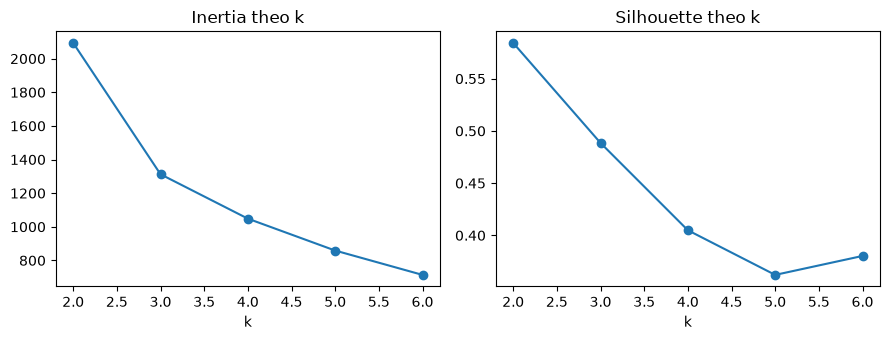

In [20]:
means_true = np.array([[7, 6], [15, 14], [12, 4]], dtype=float)
covs_true = [np.array([[5, 1], [1, 5]]), np.array([[4, -1], [-1, 6]]), np.array([[3, 0], [0, 3]])]
sizes = [60, 60, 40]
parts = [rng.multivariate_normal(m, c, size=s) for m, c, s in zip(means_true, covs_true, sizes)]
Xs = np.clip(np.vstack(parts), 0, 20)
y_hidden = np.repeat([0, 1, 2], sizes)              # nhãn thật: chỉ dùng ở mục 7

rows = []
for k in range(2, 7):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    rows.append(dict(k=k, inertia=m.inertia_, silhouette=silhouette_score(Xs, m.labels_)))
kdf = pd.DataFrame(rows)
display(kdf.round(3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(kdf.k, kdf.inertia, "o-"); ax[0].set_title("Inertia theo k"); ax[0].set_xlabel("k")
ax[1].plot(kdf.k, kdf.silhouette, "o-"); ax[1].set_title("Silhouette theo k"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

### 4.5 Gaussian Mixture: nối với phân phối Gauss
K-means gán cứng: mỗi điểm thuộc đúng một cụm. Gaussian Mixture (GMM) mô hình mỗi cụm là một phân phối Gauss nhiều chiều với tâm **µ** và hiệp phương sai **Σ** (Tuần 9 Part 1, slide 16 và 28 cho phương sai; Resources mục 2 cho Σ). Kết quả là **xác suất** thuộc từng cụm, không chỉ nhãn.

Hiệp phương sai Σ có hai ý nghĩa: đường chéo là phương sai từng đặc trưng; góc ngoài đường chéo cho biết hai đặc trưng biến thiên cùng nhau thế nào (Week 9 Part 2, slide 13). Các trục của elip đồng mức là vector riêng của Σ. Đây là lý do nên làm bài tập trong Resources mục 2 trước khi đọc tiếp.

In [21]:
gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=0).fit(Xs)
proba = gmm.predict_proba(Xs)
print("Xác suất thuộc từng cụm của 3 điểm đầu:")
print(proba[:3].round(3))

# Trục chính của cụm đầu tiên: vector riêng của Σ
evals, evecs = np.linalg.eigh(gmm.covariances_[0])
print("Trị riêng:", evals.round(3))
print("Vector riêng (mỗi cột là một trục):\n", evecs.round(3))

Xác suất thuộc từng cụm của 3 điểm đầu:
[[0.    0.793 0.207]
 [0.    0.065 0.935]
 [0.329 0.007 0.664]]
Trị riêng: [4.085 7.142]
Vector riêng (mỗi cột là một trục):
 [[-0.986 -0.168]
 [-0.168  0.986]]


Hình dưới so sánh gán cứng của K-means với xác suất của GMM. Điểm gần ranh giới có xác suất trộn lẫn; K-means không cho thấy điều đó.

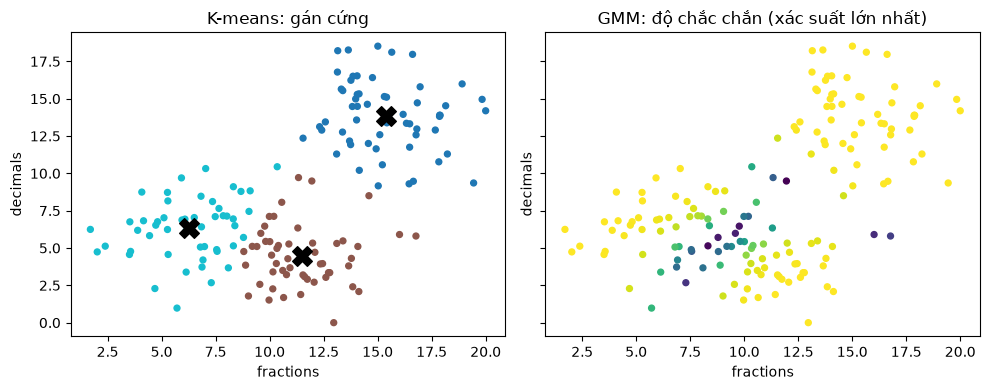

In [22]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xs)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
ax[0].scatter(Xs[:, 0], Xs[:, 1], c=km3.labels_, cmap="tab10", s=18)
ax[0].scatter(*km3.cluster_centers_.T, marker="X", s=200, c="k")
ax[0].set_title("K-means: gán cứng")
ax[1].scatter(Xs[:, 0], Xs[:, 1], c=proba.max(axis=1), cmap="viridis", s=18)
ax[1].set_title("GMM: độ chắc chắn (xác suất lớn nhất)")
for a in ax: a.set_xlabel("fractions"); a.set_ylabel("decimals")
plt.tight_layout(); plt.show()

### 4.6 Kiểm tra bằng nhãn ẩn
Nhãn thật (`y_hidden`) chỉ dùng để **kiểm tra** sau khi phân cụm xong, không dùng để huấn luyện. Có hai điều cần lưu ý:
- Tên cụm là tuỳ ý (cụm 0 của K-means có thể là nhãn thật 2), nên không so sánh trực tiếp từng số.
- Adjusted Rand Index (ARI) không phụ thuộc cách đặt tên cụm. ARI bằng 1 khi hai cách nhóm giống hệt nhau và gần 0 khi giống ngẫu nhiên.

In [23]:
ari_km = adjusted_rand_score(y_hidden, km3.labels_)
ari_gmm = adjusted_rand_score(y_hidden, gmm.predict(Xs))
print(f"ARI K-means = {ari_km:.3f}, ARI GMM = {ari_gmm:.3f}")

# Bảng đối chiếu: mỗi cụm K-means nằm chủ yếu ở nhãn thật nào
table = pd.crosstab(pd.Series(km3.labels_, name="cụm K-means"),
                    pd.Series(y_hidden, name="nhãn thật (ẩn)"))
display(table)

ARI K-means = 0.757, ARI GMM = 0.767


nhãn thật (ẩn),0,1,2
cụm K-means,,,
0,0,57,0
1,11,3,39
2,49,0,1


Lưu ý: ARI và bảng đối chiếu chỉ là kiểm tra sau khi phân cụm. Trong một bài toán thật, không có nhãn để so sánh, nên đây không thể là căn cứ duy nhất để kết luận. Giáo viên luôn là người quyết định cụm có ý nghĩa gì.

### 4.7 Dữ liệu thiếu
Từ Tuần 9 (slide 20–21): **không có phản hồi không phải là điểm 0**. Không được điền 0 mặc định. sklearn KMeans không nhận NaN nên phải xử lý trước. Hai cách chấp nhận được: loại bản ghi thiếu, hoặc điền bằng trung bình của **giá trị quan sát được** trên tập huấn luyện. Trong ví dụ dưới đây, ta kiểm tra số bản ghi bị ảnh hưởng và không điền 0.

In [24]:
Xmiss = Xs.copy()
Xmiss[[3, 17], 1] = np.nan                  # hai bản ghi thiếu điểm decimals
print("Số giá trị thiếu:", int(np.isnan(Xmiss).sum()))

try:
    KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xmiss)
except ValueError as e:
    print("KMeans báo lỗi như dự kiến:", str(e).splitlines()[0])

# Cách 1: loại bản ghi thiếu
keep = ~np.isnan(Xmiss).any(axis=1)
km_drop = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xmiss[keep])
print("Sau khi loại:", keep.sum(), "bản ghi")

# Cách 2: điền trung bình quan sát được (tính trên dữ liệu không thiếu)
col_mean = np.nanmean(Xmiss, axis=0)
Ximp = np.where(np.isnan(Xmiss), col_mean, Xmiss)
print("Trung bình dùng để điền decimals:", col_mean[1].round(3), "(không phải 0)")

Số giá trị thiếu: 2
KMeans báo lỗi như dự kiến: Input X contains NaN.
Sau khi loại: 158 bản ghi
Trung bình dùng để điền decimals: 8.425 (không phải 0)


## 5. Phân cụm trên dự án OneStopEnglish

In [25]:
if 'df' not in globals() or 'EXP' not in globals():
    print('Bỏ qua: cần df và EXP từ Group07_Notebook.ipynb. Mở notebook đó, chạy đến hết mục 7 rồi chạy lại ô này.')
else:
    assert df[EXP].isna().sum().sum() == 0, 'Có giá trị thiếu: xử lý trước khi phân cụm, không điền 0.'
    Xu = StandardScaler().fit_transform(df[EXP].values)   # chuẩn hoá không dùng nhãn

    rows = []
    for k in range(2, 6):
        m = KMeans(k, n_init=10, random_state=0).fit(Xu)
        rows.append(dict(k=k, inertia=m.inertia_, silhouette=silhouette_score(Xu, m.labels_)))
    display(pd.DataFrame(rows).round(3))

,k,inertia,silhouette
0,2,3982.541,0.252
1,3,3428.460,0.216
2,4,3092.327,0.168
3,5,2843.483,0.166


In [26]:
if 'df' in globals() and 'EXP' in globals():
    km_p = KMeans(3, n_init=10, random_state=0).fit(Xu)
    gm_p = GaussianMixture(3, covariance_type='full', random_state=0).fit(Xu)
    # Chỉ để kiểm tra, không dùng để huấn luyện
    print('ARI K-means =', round(adjusted_rand_score(y, km_p.labels_), 3))
    print('ARI GMM     =', round(adjusted_rand_score(y, gm_p.predict(Xu)), 3))
    display(pd.crosstab(pd.Series(km_p.labels_, name='cụm K-means'),
                        pd.Series(df.level.values, name='mức thật')))
    P_p = gm_p.predict_proba(Xu)
    print('Số văn bản có xác suất lớn nhất < 0,6 (gần ranh giới):', int((P_p.max(axis=1) < 0.6).sum()), 'trên', len(P_p))

ARI K-means = 0.092
ARI GMM     = 0.058


mức thật,Advanced,Elementary,Intermediate
cụm K-means,,,
0,82,20,46
1,42,130,66
2,65,39,77


Số văn bản có xác suất lớn nhất < 0,6 (gần ranh giới): 60 trên 567


Nếu ARI gần 0, các cụm không trùng với mức. Có thể phân cụm theo chủ đề hoặc độ dài văn bản thay vì mức khó. Điều này nhất quán với kết quả TF-IDF ở mục 6 của notebook dự án: các bản cùng bài rất giống nhau về từ vựng. Đây là kiểm tra mô tả; không kết luận được nguyên nhân từ chỉ số này.

## 6. Việc 2: đọc văn bản nhầm
Mục đích: tách lỗi tiền xử lý khỏi khác biệt độ khó. Ô dưới lập danh sách các văn bản nhầm hai mức (out-of-fold, cùng fold đã lưu), đặt WNL Glastonbury lên đầu, và kiểm tra câu của file gốc sau khi bỏ BOM.

In [27]:
import re
if 'folds' in globals() and 'EXP' in globals():
    X_ = df[EXP].values
    oofP = np.zeros((len(y), 3))
    for f in folds:
        tr, te = np.array(f['train']), np.array(f['test'])
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(X_[tr], y[tr])
        oofP[te] = m.predict_proba(X_[te])
    pred = oofP.argmax(axis=1)
    print('Accuracy out-of-fold (LR, 10 đặc trưng):', round((pred == y).mean(), 3))

    far = [i for i in range(len(y)) if abs(pred[i] - y[i]) == 2]
    print('Số văn bản nhầm hai mức:', len(far))
    far = sorted(far, key=lambda i: (df.article.iloc[i] != 'WNL Glastonbury', df.article.iloc[i]))

    def raw_sent_stats(t):
        t = t.replace('\ufeff', '')
        ss = [s for s in re.split(r'(?<=[.!?])\s+', t) if s.strip()]
        return len(ss), round(sum(len(s.split()) for s in ss) / len(ss), 1), max(len(s.split()) for s in ss)

    rows = []
    for i in far[:10]:
        n, avg, mx = raw_sent_stats(texts[i])
        rows.append({'bài': df.article.iloc[i], 'mức thật': df.level.iloc[i],
                     'dự đoán': LEVELS_W10[pred[i]], 'số câu (regex)': n,
                     'từ/câu (regex)': avg, 'câu dài nhất': mx})
    display(pd.DataFrame(rows))
    print('Văn bản đầu tiên cần đọc:', df.article.iloc[far[0]], '-', df.level.iloc[far[0]])
    print(texts[far[0]][:400].replace('\n', ' / '))

Accuracy out-of-fold (LR, 10 đặc trưng): 0.637
Số văn bản nhầm hai mức: 28


,bài,mức thật,dự đoán,số câu (regex),từ/câu (regex),câu dài nhất
0,WNL Glastonbury,Elementary,Advanced,20,17.1,39
1,Amsterdam,Elementary,Advanced,21,21.2,44
2,Billionaires,Elementary,Advanced,16,23.9,47
3,Bolivia,Elementary,Advanced,29,20.0,45
4,Cigarettes,Elementary,Advanced,20,23.9,56
5,Fitness,Advanced,Elementary,37,21.8,50
6,Gangs,Advanced,Elementary,61,16.8,46
7,Japan,Advanced,Elementary,59,16.4,62
8,Midlife crisis,Elementary,Advanced,22,20.9,34
9,Norwegian sun,Advanced,Elementary,49,18.8,73


Văn bản đầu tiên cần đọc: WNL Glastonbury - Elementary
﻿Glastonbury Festival wants to fight a war against plastic water bottles. They plan to become the world’s most environmentally friendly outdoor music event.  / Each year, disposable bottles leave the Somerset festival site covered in plastic. About one million plastic bottles are used during the festival.  / The festival organizers will give stainless-steel reusable bottles to all band members. Thousa


**Ghi chú đọc 10 ca nhầm (số liệu từ lần chạy với spaCy thật, ngày 25/10/2026).** Claude đã đọc toàn văn bản bị nhầm của cả 10 bài và so sánh ba phiên bản của từng bài; nhóm nên xem lại cột cuối trước khi nộp. P = xác suất của mức dự đoán; SD = độ lệch chuẩn so với trung bình mức thật.

| Bài | Mức thật | Dự đoán (P) | Có lỗi tiền xử lý không? (tiêu đề, BOM, tách câu sai) | Khác biệt do độ khó? (từ vựng, ý, cấu trúc) | Kết luận |
|---|---|---|---|---|---|
| WNL Glastonbury | Elementary | Advanced (0,50) | Không. Cả ba bản đều có BOM; bản Elementary có 20 câu, tách đúng. | Có. Câu ngắn (17,1 từ mỗi câu theo regex, bản Advanced 26,6) nhưng từ vựng vẫn nặng: độ dài từ và tỷ lệ từ dài cao hơn mức Elementary khoảng 1,8 đến 2,1 SD (stainless-steel, environmentally, ecosystems). Zipf trung bình gần bằng bản Advanced (5,61 so với 5,56). Đọc toàn văn: câu đơn giản, không có lỗi bản gốc. | Lỗi do đặc trưng: bản Elementary đã đơn giản hoá cấu trúc nhưng không đơn giản hoá từ vựng. Độ dài câu không giải thích được ca này (trả lời câu hỏi 2). |
| Amsterdam | Elementary | Advanced (0,53) | Không đáng kể. Bản gốc có lỗi ngữ pháp ("The plan is hopes to"). | Có. Bản Elementary vẫn giữ câu dài (20,1 từ mỗi câu, câu dài nhất 44 từ) và nhiều mệnh đề phụ (1,64 mỗi câu, cao hơn mức Elementary 1,5 SD), gần bản Advanced (23,6 và 1,58). | Bản viết lại ít đơn giản hoá cấu trúc; nhãn mức có thể hơi nhiễu. Thứ tự trong bài vẫn đúng (độ dài câu tăng dần theo mức). |
| Billionaires | Elementary | Advanced (0,47; Elementary 0,31) | Một phần. Regex không tách câu sau dấu nháy đóng, nên "câu dài nhất" 47 từ thực ra là hai câu dính nhau. Mô hình dùng spaCy nên không bị ảnh hưởng. | Có. Mệnh đề phụ nhiều (1,56 mỗi câu, +1,3 SD), nhiều số liệu và câu trích dẫn dài. | Ca sát ranh giới (0,31 / 0,22 / 0,47); khó do cấu trúc câu. |
| Bolivia | Elementary | Advanced (0,73) | Một phần. Cùng lỗi regex ở trên (bản Advanced có "câu" 92 từ do dính câu trích dẫn). | Có. Từ dài nhiều (+1,5 SD), p10 Zipf thấp (indigenous, exemption, convention), TTR thấp (−1,5 SD) vì lặp "coca" và "Bolivia". Bản Elementary còn giữ nhiều đoạn trích nguyên văn từ tuyên bố chính thức của Anh và Nga. | Từ vựng thuật ngữ và chủ đề kéo mức lên. |
| Cigarettes | Elementary | Advanced (0,77) | Không đáng kể. Bản gốc có lỗi chính tả ("do not to be need regulated"). | Có. Câu dài 20,8 từ (+1,1 SD), từ dài +1,7 SD (regulated, advertising, electronic), nhiều đoạn trích nguyên văn từ tuyên bố của Bộ Y tế Anh. Cả ba bản đều bị đoán Advanced nhưng thứ tự vẫn đúng (20,8 < 26,3 < 28,5 từ mỗi câu). | Sai mức tuyệt đối, đúng thứ tự tương đối. |
| Fitness | Advanced | Elementary (0,47; Intermediate 0,46) | Không. 807 từ, 37 câu, tách bình thường. | Có. Câu ngắn (17,5 từ, −1,2 SD), từ ngắn (−1,8 SD), nhiều lời thoại trực tiếp ("Who's that huffing and panting?"). Độ khó của bản Advanced nằm ở độ dài (807 từ so với 604 từ của bản Elementary) và ở tham chiếu văn hoá Anh (Eileen Fowler, Buckingham Palace, University of the Third Age), mô hình không đo hai thứ này. | Ca sát ranh giới giữa Elementary và Intermediate; văn kể chuyện, nhiều lời nói kéo mức xuống. |
| Gangs | Advanced | Elementary (0,92) | Không. 1027 từ, 61 câu; BOM có ở cả ba bản. | Có. Văn phong phỏng vấn, ngôi thứ nhất: câu 14,9 từ (−1,9 SD), Zipf trung bình cao (+1,8 SD), từ ngắn. Cả ba bản đều bị đoán Elementary. Đọc toàn văn vẫn thấy từ trừu tượng rải rác (nullified, prevalent, redemption, "index offence") nhưng quá ít để đẩy các trung bình lên. | Ca chắc chắn nhất trong 10 ca: bản Advanced khó chủ yếu vì độ dài và nội dung, hai thứ mô hình không đo. Nên nêu trong báo cáo. |
| Japan | Advanced | Elementary (0,70) | Một phần. Bản Advanced có "câu" 62 từ do regex dính câu trích dẫn; spaCy cho 14,6 từ mỗi câu. | Có. Giọng văn nói, câu ngắn (−2,0 SD), ít mệnh đề phụ (0,86; −1,5 SD), Zipf cao. Độ khó còn nằm ở tham chiếu văn hoá (Sun Tzu, Achilles' heel, Blade Runner, David và Goliath), mô hình không đo được. | Giống Gangs: mô hình mù với văn phong. |
| Midlife crisis | Elementary | Advanced (0,46; Intermediate 0,33) | Không. | Có. Từ hiếm theo chủ đề khoa học (chimpanzees, orangutans, sceptical, sportscar): p10 Zipf thấp (−2,5 SD), tỷ lệ từ hiếm +1,7 SD, dù câu chỉ dài vừa (19,1 từ). | Từ vựng chủ đề kéo mức lên; không phải lỗi tiền xử lý. |
| Norwegian sun | Advanced | Elementary (0,49; Intermediate 0,42) | Chưa kết luận. Văn bản có dấu cách thừa trước dấu phẩy ("Solspeil , or Sun mirror ,") và regex ra câu 80 từ; chưa kiểm tra tác động lên spaCy. | Có. Câu ngắn (16,1 từ, −1,6 SD), ít mệnh đề phụ (−1,6 SD), nhưng tỷ lệ từ hiếm cao (+2,0 SD) vì tên riêng nước ngoài (Rjukan, Gaustatoppen, Solspeil). | Tín hiệu mâu thuẫn, sát ranh giới; tên riêng làm tỷ lệ từ hiếm không còn nghĩa là "khó". |

**Nhận xét chung sau khi đọc.** (1) Với cả 10 bài, cả ba phiên bản của cùng bài đều bị đoán cùng một mức, tức mô hình chủ yếu chấm bài (chủ đề, văn phong), ít chấm phiên bản. Điều này khớp với RA 0,915 cao hơn accuracy tuyệt đối 0,637 ở mục 7. (2) Chưa thấy lỗi tiền xử lý làm lệch kết quả: BOM có ở mọi file nên không tạo khác biệt giữa các mức; hai bảng cùng thứ tự hàng (ô 8 chạy qua). (3) Một điểm cần ghi vào giới hạn: regex tách câu của ô 36 không tách sau dấu nháy đóng, nên cột "câu dài nhất" phóng đại; đặc trưng của mô hình dùng spaCy nên không bị ảnh hưởng.


## 7. Hướng mở rộng: xếp hạng trong bài và gán mức tuyệt đối
Mỗi bài có đủ ba phiên bản. Hai câu hỏi đặt cạnh nhau: (a) mô hình xếp đúng thứ tự ba phiên bản của một bài bao nhiêu phần trăm; (b) khi nhìn một văn bản riêng lẻ, nó gán đúng mức tuyệt đối bao nhiêu phần trăm. Tỉ lệ bộ ba xếp đúng thứ tự (RA) theo cách đo của nhóm: tỉ lệ bộ ba mà điểm kỳ vọng của cả ba phiên bản được xếp đúng thứ tự Elementary < Intermediate < Advanced. Trong phần bài Pan và cộng sự (2025) mà nhóm đọc được (mục 1 đến 4) không có chỉ số tên RA, chỉ có accuracy, F1, precision và recall; phần kết quả chưa đọc được, nên chưa gán định nghĩa này cho Pan. Nếu muốn trích, cần đọc mục kết quả của bài gốc.

In [28]:
if 'oofP' in globals():
    E = oofP @ np.arange(3)                         # điểm xếp hạng: kỳ vọng mức
    art_idx = {}
    for i, (a, l) in enumerate(zip(df.article, df.level)):
        art_idx.setdefault(a, {})[ORD_W10[l]] = i
    triples = [d for d in art_idx.values() if len(d) == 3]
    ra = sum(E[d[0]] < E[d[1]] < E[d[2]] for d in triples) / len(triples)
    pair_ok = sum(E[d[a]] < E[d[b]] for d in triples for a, b in [(0, 1), (1, 2), (0, 2)]) / (3 * len(triples))
    abs_acc = (pred == y).mean()
    print(f'Bộ ba xếp đúng thứ tự (RA): {ra:.3f} trên {len(triples)} bài')
    print(f'Cặp xếp đúng thứ tự:        {pair_ok:.3f}')
    print(f'Accuracy gán mức tuyệt đối: {abs_acc:.3f}')
    print('Chênh lệch giữa hai con số cho biết độ khó tương đối hay tuyệt đối (xem nhận xét thầy).')

Bộ ba xếp đúng thứ tự (RA): 0.915 trên 189 bài
Cặp xếp đúng thứ tự:        0.968
Accuracy gán mức tuyệt đối: 0.637
Chênh lệch giữa hai con số cho biết độ khó tương đối hay tuyệt đối (xem nhận xét thầy).


## 8. Việc 3: năm văn bản ngoài bộ dữ liệu
Nhãn phải được nhóm gán **độc lập, trước khi chạy mô hình**. Ghi nhãn vào `external_texts_labels.csv` (cột: `name`, `file`, `label`, `label_date`), đặt nội dung trong thư mục `external_texts/`. Ô dưới đọc nhãn đã ghi, rồi mới chạy dự đoán. Code không kiểm tra được việc gán độc lập; đó là quy trình của nhóm.

In [29]:
EXT_FILE, EXT_DIR = 'external_texts_labels.csv', 'external_texts'
if 'df' not in globals() or 'EXP' not in globals() or 'extract' not in globals():
    print('Bỏ qua: cần df, EXP và hàm extract() từ notebook dự án.')
elif not os.path.exists(EXT_FILE):
    print('Chưa có', EXT_FILE, '. Tạo file với 5 dòng và điền nhãn trước khi chạy ô này.')
else:
    ext = pd.read_csv(EXT_FILE)
    assert len(ext) == 5, 'Cần đúng 5 văn bản'
    assert ext.label.notna().all() and ext.label_date.notna().all(), 'Thiếu nhãn hoặc ngày gán'
    assert set(ext.label) <= set(LEVELS_W10), 'Nhãn phải là Elementary, Intermediate hoặc Advanced'
    final = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(X_, y)
    out = []
    for _, r in ext.iterrows():
        t = open(os.path.join(EXT_DIR, r.file), encoding='utf-8').read()
        f_ = pd.DataFrame([extract(t)])[EXP].values
        p = final.predict_proba(f_)[0]
        out.append({'văn bản': r['name'], 'nhãn nhóm': r.label, 'ngày gán': r.label_date,
                    'dự đoán': LEVELS_W10[int(p.argmax())], 'xác suất lớn nhất': round(p.max(), 3)})
    display(pd.DataFrame(out))

,văn bản,nhãn nhóm,ngày gán,dự đoán,xác suất lớn nhất
0,Simple Wikipedia - Volcano,Elementary,2026-10-25,Advanced,0.752
1,Simple Wikipedia - Tornado,Intermediate,2026-10-25,Advanced,0.746
2,Alice in Wonderland ch.1 (Carroll 1865),Intermediate,2026-10-25,Advanced,0.995
3,Wikipedia - Inflation,Advanced,2026-10-25,Advanced,0.930
4,Darwin - Origin of Species intro (1859),Advanced,2026-10-25,Advanced,0.982


**Kết quả mục 8 (spaCy thật).** Mô hình đoán 2 trên 5 văn bản đúng nhãn đã gán (Inflation và Darwin, cả hai Advanced); cả 5 văn bản đều bị đoán Advanced.

**Lưu ý về nhãn.** Năm nhãn trong `external_texts_labels.csv` do Claude gán ngày 25/10/2026 lúc 14:10, trước khi chạy dự đoán, kèm lý do ở cột `rationale`. Đây không phải nhãn do nhóm thảo luận như yêu cầu ban đầu, nên nhóm cần đọc lại các văn bản trong `external_texts/`, sửa nhãn nếu không đồng ý và ghi lại ngày gán, rồi chạy lại ô trên.

**Nhận xét.** Hai văn bản Wikipedia bản đơn giản (Volcano, Tornado) và Alice in Wonderland bị đoán Advanced với xác suất 0,75 đến 0,995. Cùng chiều với mục 6: mô hình coi từ hiếm theo chủ đề (mantle plumes, mesocyclone) và câu dài kiểu thế kỷ 19 là dấu hiệu "khó". Cả ba văn bản này nằm ngoài thể loại báo của OneStopEnglish, nên 2/5 chỉ là một phép thử nhỏ về độ lệch miền dữ liệu, chưa đủ để kết luận về độ chính xác.


## 9. Trích dẫn và tài liệu
- Vajjala, S. & Lučić, I. (2018). OneStopEnglish corpus: A new corpus for automatic readability assessment and text simplification. *Proceedings of the 13th Workshop on Innovative Use of NLP for Building Educational Applications (BEA)*, trang 297–304. Đã xác minh DOI 10.18653/v1/W18-0535.
- Lee, B. W., Jang, Y. S. & Lee, J. (2021). Pushing on text readability assessment: A transformer meets handcrafted linguistic features. *Proceedings of EMNLP 2021*, trang 10669–10686. DOI 10.18653/v1/2021.emnlp-main.834. **Đã xác minh thông tin thư mục.** Cách chia dữ liệu của bài: **stratified k-fold (k = 5; train 0.8, val 0.1, test 0.1)** (mục Datasets and Evaluation Setups, bản arXiv 2109.12258). Bài báo báo cáo 99% accuracy trên OneStopEnglish (RoBERTa kết hợp đặc trưng thủ công) và không nói có gộp ba phiên bản của một bài vào cùng một phía hay không. Nếu không gộp, các bản cùng bài có thể nằm ở cả train và test, và con số đó không so sánh trực tiếp được với kết quả chia theo bài của nhóm.
- Pan, W., Li, X., Chen, X. & Xu, R. (2025). Textual form features for text readability assessment. *Natural Language Processing*, 31, trang 800–841. DOI 10.1017/nlp.2024.50. **Đã xác minh thông tin thư mục.** Phần bài đọc được (mục 1 đến 4) không có chỉ số RA; xem ghi chú ở mục 7.
- Guo, C., Pleiss, G., Sun, Y. & Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML*. (Dùng ở notebook W9.)

## 10. Bài tập và câu hỏi

**Câu hỏi của thầy**

**1. Nếu chia ngẫu nhiên mà accuracy vẫn bằng đoán bừa, các em sẽ kiểm tra bước nào đầu tiên?**
Trả lời: Bước đầu tiên là căn chỉnh dữ liệu: in vài mẫu ID–text–label, kiểm X, y, groups cùng thứ tự và fold áp đúng X, y. Nếu căn chỉnh đúng mà accuracy vẫn gần 1/3, bước tiếp theo là đo láng giềng gần nhất (mục 3): nếu phần lớn là bản anh em khác mức, nguyên nhân là hiệu ứng cùng bài, không phải lỗi mã.

**2. Một bản Elementary có câu dài như bản Advanced thì điều gì khác khiến người viết lại vẫn xếp nó là Elementary?**
Trả lời: Trên toàn bộ corpus, bản Elementary dùng từ thông dụng hơn một chút (Zipf trung bình 5,83 so với 5,73 của Advanced) và câu ngắn hơn rõ rệt (khoảng 17 so với 22 từ mỗi câu, theo spaCy). Với WNL Glastonbury, bản Elementary vẫn ngắn hơn bản Advanced của chính nó (17 so với 27 từ mỗi câu, tách bằng regex), nên độ dài câu không giải thích được lỗi ở ca này. Cần nhìn đặc trưng khác; đây cũng là lý do một đặc trưng đơn lẻ không đủ.

**Ba bản của cùng một bài nằm ở cả train và test thì câu hỏi khái quát đã thay đổi thế nào?**
Trả lời: Mô hình được đánh giá trên bài nó đã thấy, nên accuracy đo khả năng nhớ từ vựng của bài chứ không đo khả năng đọc độ khó. Khi chia theo bài, mỗi bài chỉ nằm một phía, nên kết quả phản ánh khả năng khái quát sang bài mới.

**Bài tập Tuần 10** (làm trên giấy trước, rồi chạy ô 44)
- **Bài 1 (K-means bằng tay):** tính khoảng cách bình phương, gán cụm, tính tâm mới với tâm khởi tạo (5, 5) và (15, 15). Kết quả một vòng và kết quả hội tụ được in ở ô 44.
- **Bài 2 (chọn k):** n_init=1 cho inertia lớn hơn hoặc bằng n_init=10. Lý do: n_init=1 chỉ có một lần khởi tạo, có thể rơi vào cực trị cục bộ; n_init=10 lấy kết quả tốt nhất trong mười lần khởi tạo.
- **Bài 3 (ARI):** ARI không đổi khi đổi tên cụm, vì ARI chỉ xét từng cặp điểm có cùng cụm hay không, không phụ thuộc vào số nhãn. Kết quả in ở ô 44 xác nhận điều này.
- **Bài 4 (giải thích):** K-means gán cứng, chỉ dựa vào khoảng cách tới tâm, nên không cho biết điểm nào chắc chắn. GMM có ma trận hiệp phương sai Σ và cho xác suất thuộc từng cụm, nên thấy được các điểm gần ranh giới. Cụm K-means luôn có dạng gần cầu, còn cụm GMM có thể là elip theo hướng của Σ.

In [30]:
# Bài 1: K-means bằng tay, tâm khởi tạo (5,5) và (15,15)
init1 = np.array([[5, 5], [15, 15]], dtype=float)
D = np.stack([sq_dist(X, c) for c in init1], axis=1)   # khoảng cách bình phương, 8 x 2
print('Khoảng cách bình phương:\n', D)
g1 = D.argmin(axis=1)
print('Gán cụm sau một vòng:', g1)
print('Tâm mới sau một vòng:\n', np.array([X[g1 == k].mean(axis=0) for k in range(2)]))
labels1, centres1, it1 = kmeans_scratch(X, centres=init1)
print('Số vòng đến hội tụ:', it1, '| tâm cuối:', centres1.tolist())

# Bài 2: so sánh inertia giữa n_init=1 và n_init=10 (cùng k=3)
for n in [1, 10]:
    m = KMeans(n_clusters=3, n_init=n, random_state=0).fit(Xs)
    print(f'n_init={n}: inertia={m.inertia_:.3f}')

# Bài 3: đổi tên cụm (0↔2) rồi tính lại ARI
relabelled = np.array([2, 1, 0])[km3.labels_]
print('ARI gốc:', round(adjusted_rand_score(y_hidden, km3.labels_), 3))
print('ARI sau khi đổi tên cụm:', round(adjusted_rand_score(y_hidden, relabelled), 3))

Khoảng cách bình phương:
 [[  5. 265.]
 [  5. 145.]
 [  9. 149.]
 [ 41.  61.]
 [ 85.  25.]
 [181.   1.]
 [185.   5.]
 [313.  13.]]
Gán cụm sau một vòng: [0 0 0 0 1 1 1 1]
Tâm mới sau một vòng:
 [[ 7.  6.]
 [15. 14.]]
Số vòng đến hội tụ: 2 | tâm cuối: [[7.0, 6.0], [15.0, 14.0]]
n_init=1: inertia=1312.359
n_init=10: inertia=1312.359
ARI gốc: 0.757
ARI sau khi đổi tên cụm: 0.757


## 11. Kiểm tra trước khi nộp
- [x] Mục 2: hai bảng cùng thứ tự hàng; in được mẫu ID–text–label.
- [x] Mục 2: `folds_w10.json` đã lưu; chạy lại vẫn khớp.
- [ ] Mục 3: đã đọc lại và ghi lý do chênh lệch 0,841 và 0,336, kèm bằng chứng. (Số đã chạy lại: 0,838 và 0,337; láng giềng cùng bài 0,981, cùng mức 0,011. Còn việc trao đổi với thầy.)
- [x] Mục 6: có ít nhất 10 dòng ghi chú đọc, bắt đầu từ WNL Glastonbury.
- [x] Mục 7: có RA và accuracy tuyệt đối, cùng một bộ fold.
- [ ] Mục 8: đủ 5 văn bản, nhãn có ngày gán, gán trước khi chạy. (Đủ 5 văn bản, nhãn gán 25/10/2026 14:10 trước khi chạy, nhưng do Claude gán; nhóm cần rà lại nhãn.)
- [x] Mục 9: hai trích dẫn đã xác minh; đã thêm cách chia dữ liệu của Lee et al. (RA chưa tìm thấy trong bài Pan et al., đã ghi ở mục 7).
- [x] Mục 10: hai câu hỏi của thầy đã trả lời.

## 12. Kết luận
- Phân cụm học cấu trúc từ dữ liệu không nhãn bằng cách lặp gán và cập nhật tâm. Các công thức khoảng cách và trung bình giống Tuần 9.
- Chọn k bằng inertia và silhouette, không bằng accuracy vì không có nhãn.
- Thang đo ảnh hưởng đến khoảng cách; chuẩn hoá học từ dữ liệu, không dùng nhãn.
- GMM mô hình hoá từng cụm bằng µ và Σ, cho xác suất thay vì nhãn cứng. Đây là chỗ hiệp phương sai và vector riêng xuất hiện.
- Dữ liệu thiếu không được điền 0. Phải xử lý rõ ràng trước khi phân cụm.
- Cụm chỉ là gợi ý. Giáo viên kiểm tra bản ghi và bối cảnh trước khi đặt tên hoặc đưa ra quyết định.

**Câu hỏi để tự trả lời:** Nếu hai cụm có tâm gần nhau và chỉ số silhouette thấp, điều đó nói lên gì về dữ liệu, và bạn sẽ kiểm tra bước nào tiếp theo?

**Trả lời câu hỏi tự trả lời:** Hai cụm có tâm gần nhau và silhouette thấp cho thấy dữ liệu chồng lấn, không có ranh giới rõ. Điều đó không chứng minh có đúng hai nhóm thật. Bước tiếp theo là đọc lại bản ghi và bối cảnh của dữ liệu trước khi quyết định có tách cụm hay không.